# NewsBot Intelligence System

**Individual portfolio project by Kameron Walters**  
ITAI 2373 Natural Language Processing

This notebook implements an end-to-end news intelligence pipeline using the recommended BBC News Classification dataset. It preprocesses full articles, analyzes TF-IDF features, POS and dependency patterns, sentiment, named entities, and compares three supervised classifiers.

## Reproducibility and setup

Run this notebook from the project root. The included pipeline uses a fixed random seed (`42`) and a stratified 80/20 train-test split. In Google Colab, install the packages below and upload the project folder first.

In [ ]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn nltk spacy joblib
!python -m spacy download en_core_web_sm -q

In [ ]:
from pathlib import Path
import json, sys
PROJECT = Path.cwd()
if not (PROJECT / 'newsbot_pipeline.py').exists():
    raise FileNotFoundError('Open this notebook from the ITAI2373-NewsBot-Midterm folder.')
sys.path.insert(0, str(PROJECT))

## 1 Business context and dataset

Editors, communications teams, and media analysts need a consistent way to triage large news feeds. NewsBot assigns each article to one of five editorial desks and adds interpretable metadata: sentiment, entities, discriminative terms, grammatical patterns, and syntactic relationships. The Kaggle training file contains 1,490 labeled articles across business, entertainment, politics, sport, and tech.

In [1]:
from newsbot_pipeline import run_pipeline
summary = run_pipeline(project_dir=PROJECT)
summary

{
  "source_rows": 1490,
  "analysis_rows": 1440,
  "missing_rows_removed": 0,
  "duplicate_articles_removed": 50,
  "categories": {
    "business": 335,
    "entertainment": 263,
    "politics": 266,
    "sport": 342,
    "tech": 234
  },
  "train_rows": 1152,
  "test_rows": 288,
  "random_seed": 42,
  "best_model": "Linear SVM",
  "best_accuracy": 0.96875,
  "best_macro_f1": 0.9672444617963901,
  "vocabulary_size": 20000,
  "mean_words_per_article": 385.49861111111113,
  "median_words_per_article": 338.0,
  "sentiment_means": {
    "business": 0.23816835820895524,
    "entertainment": 0.5903463878326997,
    "politics": 0.04948045112781955,
    "sport": 0.5492090643274854,
    "tech": 0.5329713675213675
  },
  "entity_sample_articles": 500
}


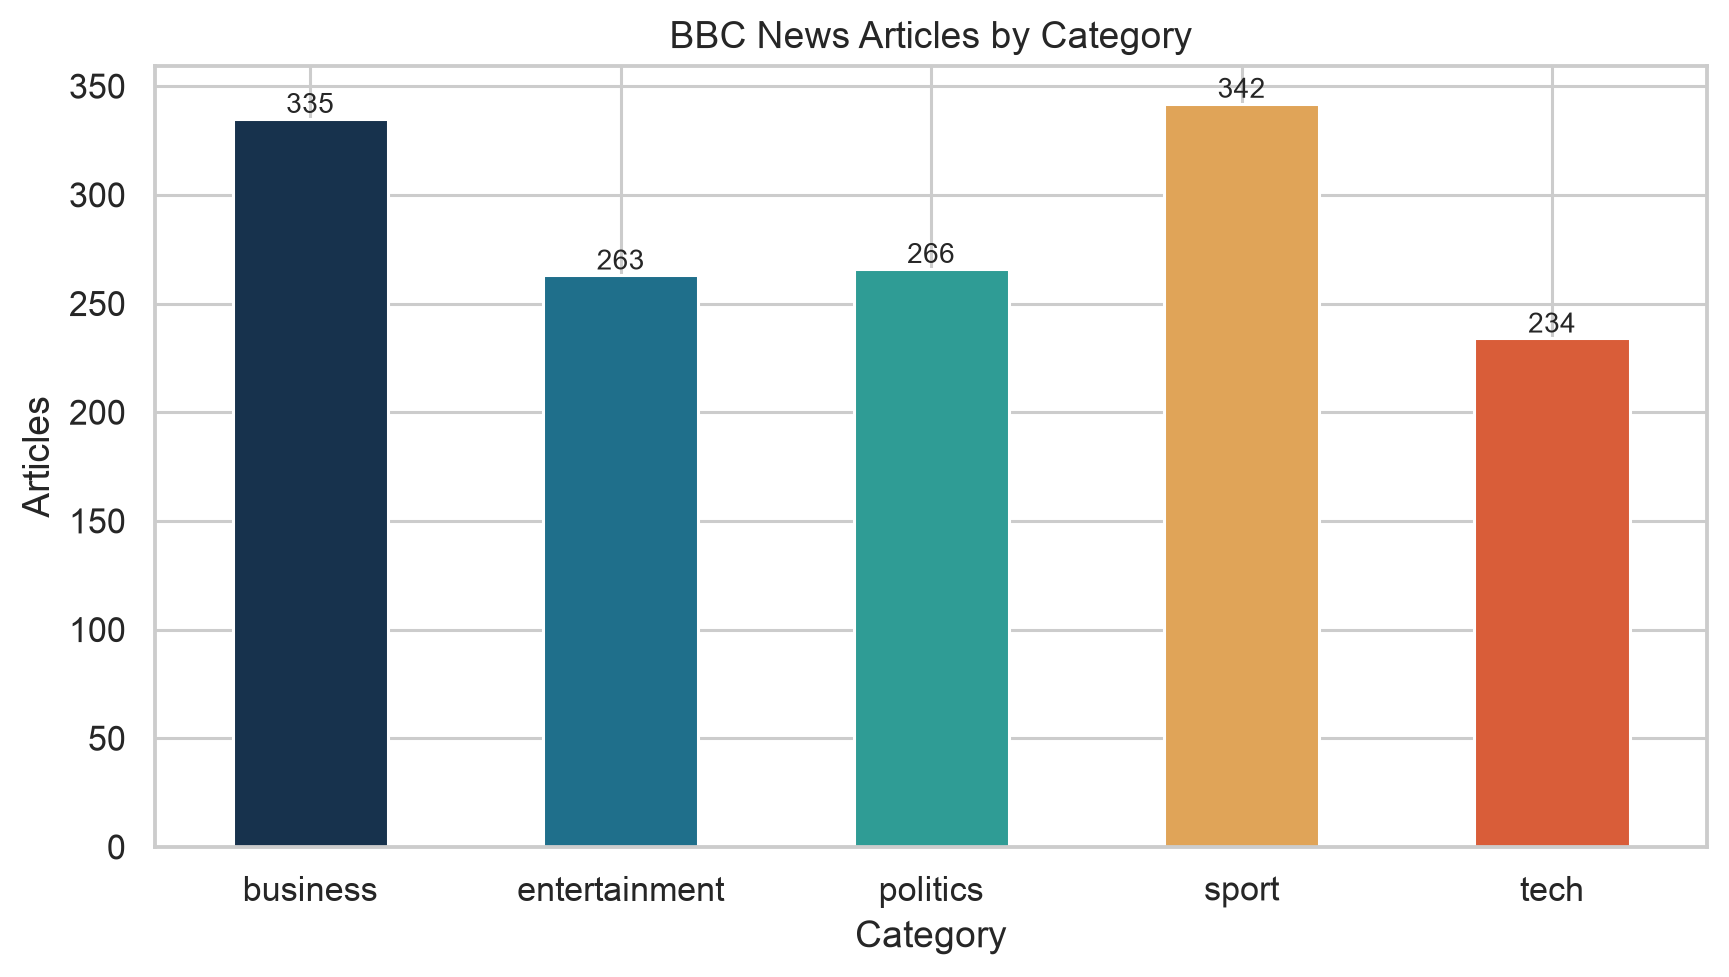

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/01_category_distribution.png'))

## 2 Text preprocessing

The reusable cleaner normalizes whitespace and removes web/email noise while preserving punctuation and monetary symbols used by sentiment and entity extraction. Rows missing text or labels are removed, and exact duplicate articles are excluded before splitting to prevent leakage. The classifier uses TF-IDF stop-word filtering instead of destructively removing words from the shared article representation; spaCy provides tokenization and lemmatization for linguistic analysis.

In [1]:
from newsbot_pipeline import clean_text
example = 'Email desk@example.com — Markets rose 5% at https://example.com.'
print(clean_text(example))

Email EMAIL Markets rose 5% at URL .


## 3 TF-IDF feature extraction and category language

TF-IDF uses unigrams and bigrams, sublinear term frequency, a minimum document frequency of two, and a 20,000-feature cap. These settings preserve meaningful phrases while controlling memory use. The feature-weight chart shows the terms that most strongly distinguish each desk in the best classifier.

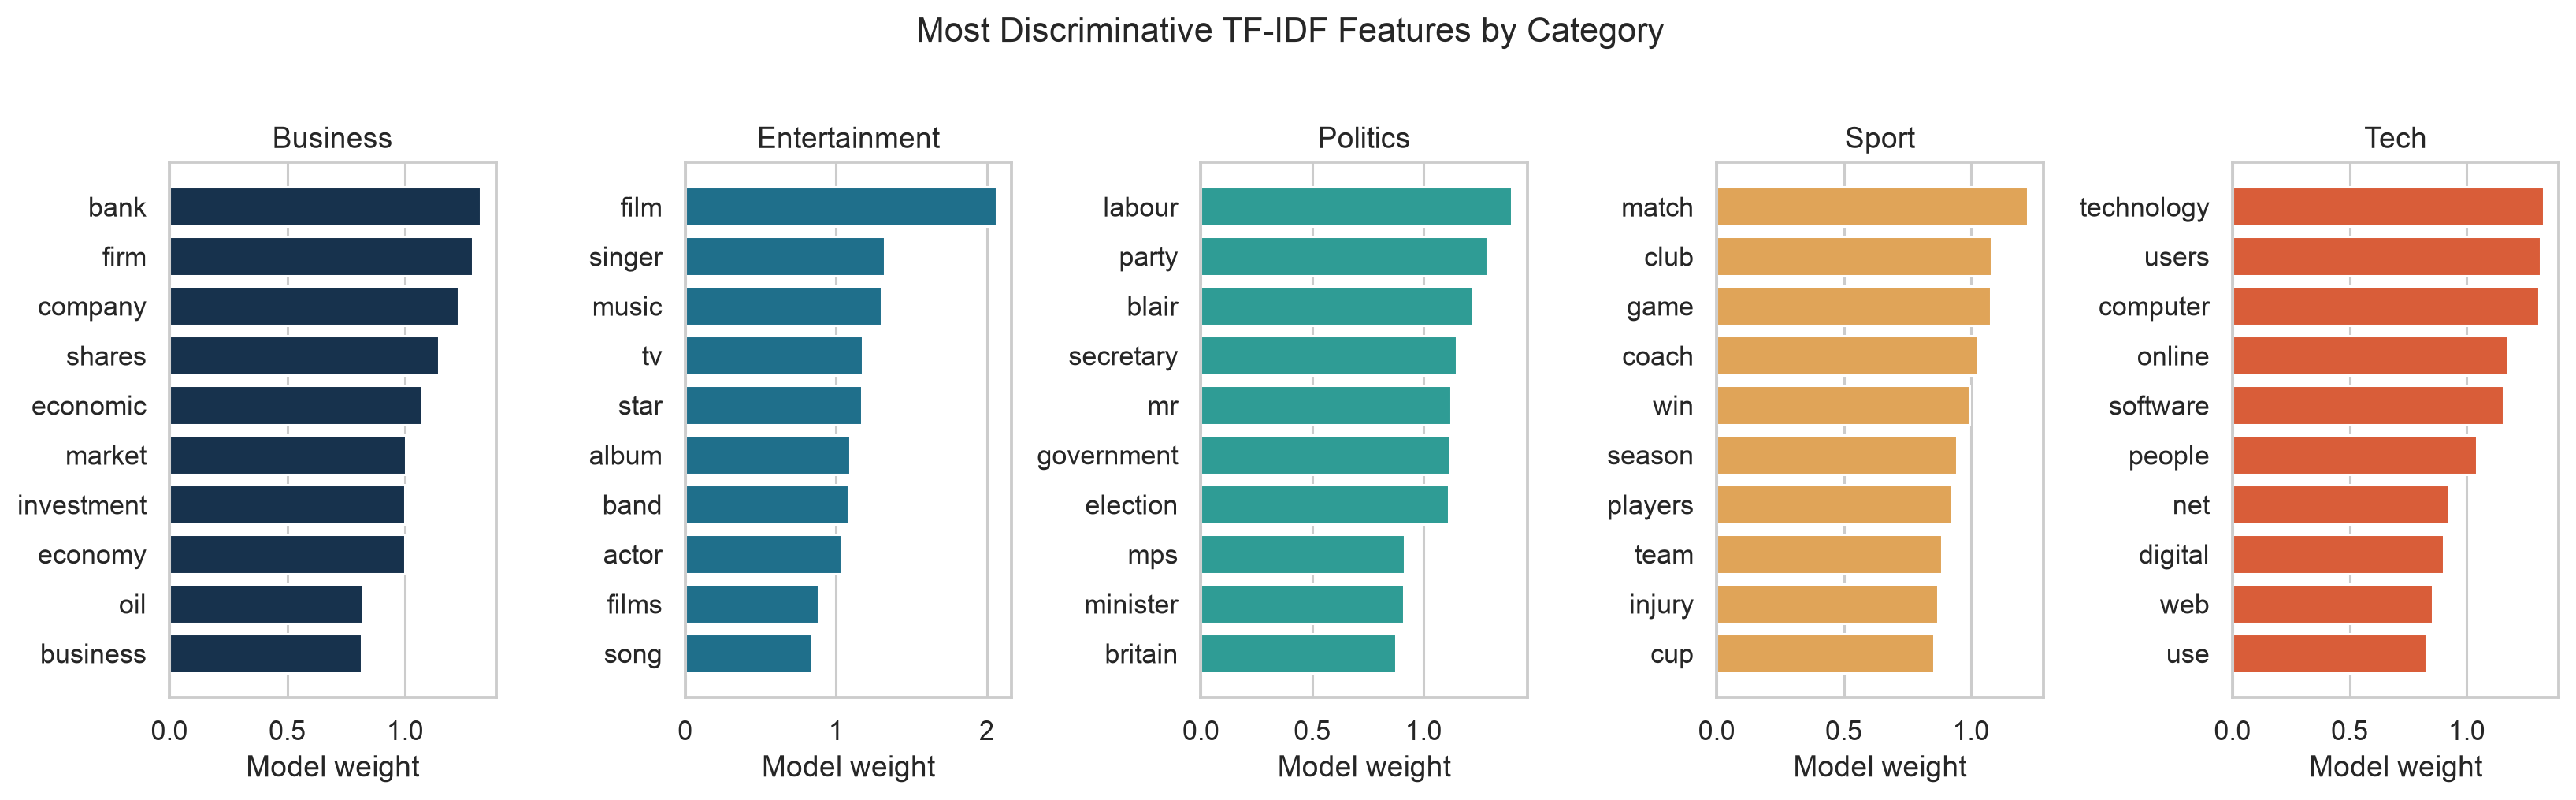

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/04_top_terms.png'))

## 4 Part-of-speech and syntax analysis

A reproducible stratified sample of 100 articles per category is processed with spaCy. POS shares reveal writing-style differences, while dependency counts for subjects, objects, modifiers, roots, and compounds capture sentence structure. The complete category tables are saved in `results/pos_distribution.csv` and `results/dependency_distribution.csv`.

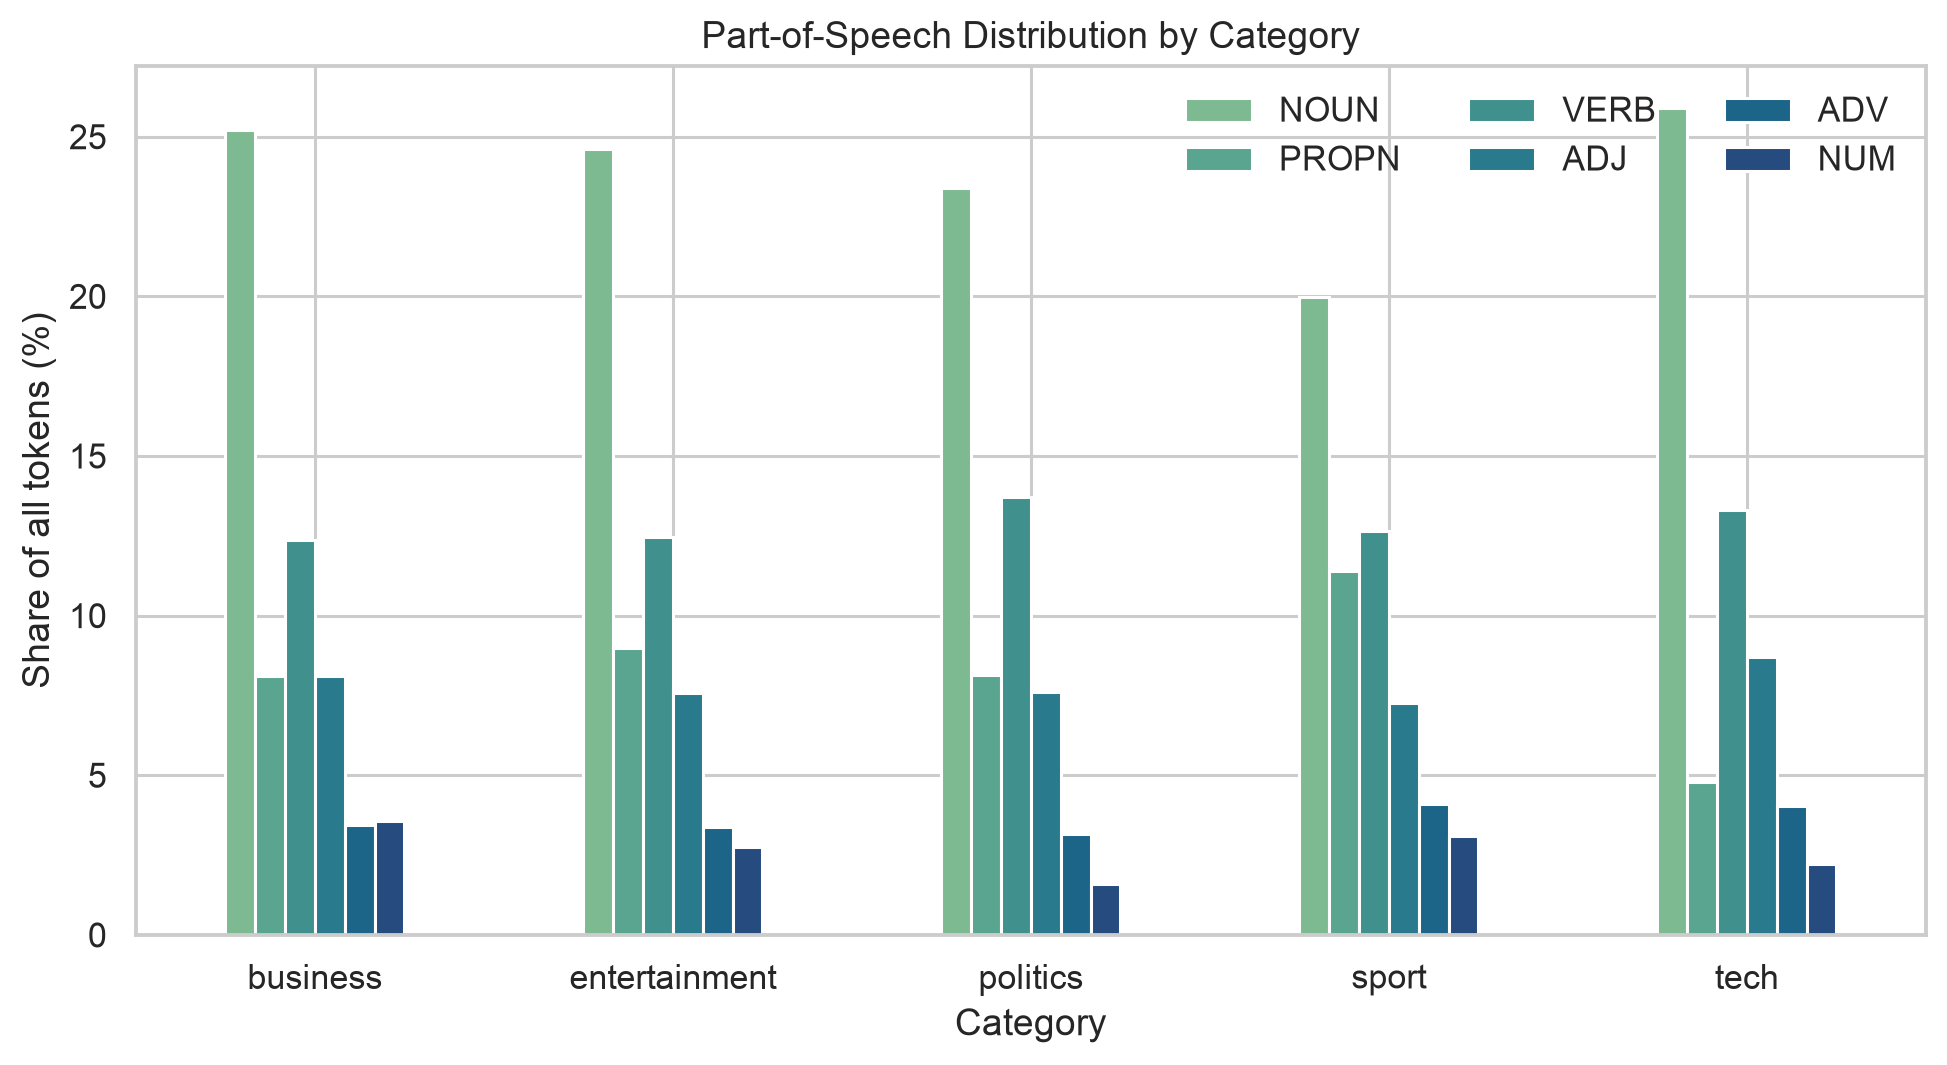

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/07_pos_distribution.png'))

## 5 Sentiment and emotional tone

VADER produces article-level compound sentiment scores from -1 to +1. Because news language is factual and domain-specific, these values are best interpreted as lexical tone rather than reader emotion. The category comparison highlights distributional differences and outliers.

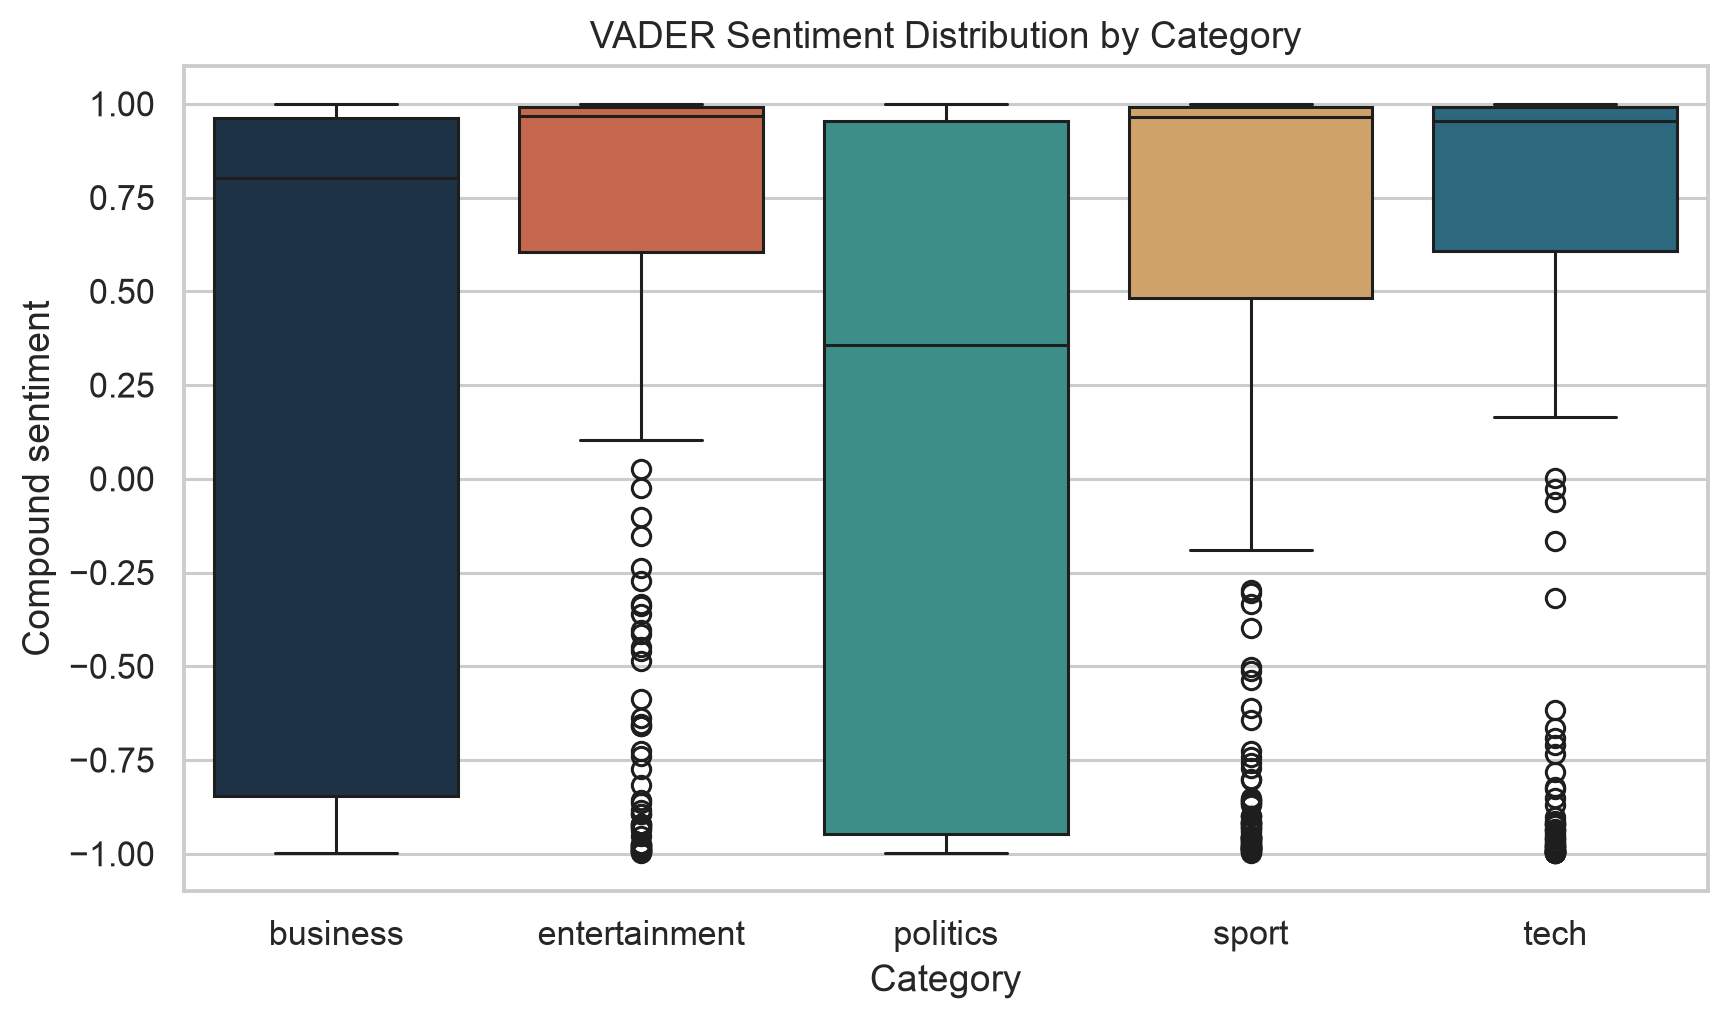

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/05_sentiment_by_category.png'))

## 6 Multi-class classification

Multinomial Naive Bayes, logistic regression, and a linear support-vector machine use the same split and TF-IDF design. Accuracy measures total correctness, while macro F1 gives every category equal weight. The selected Linear SVM achieved **96.9% accuracy** and **96.7% macro F1**.

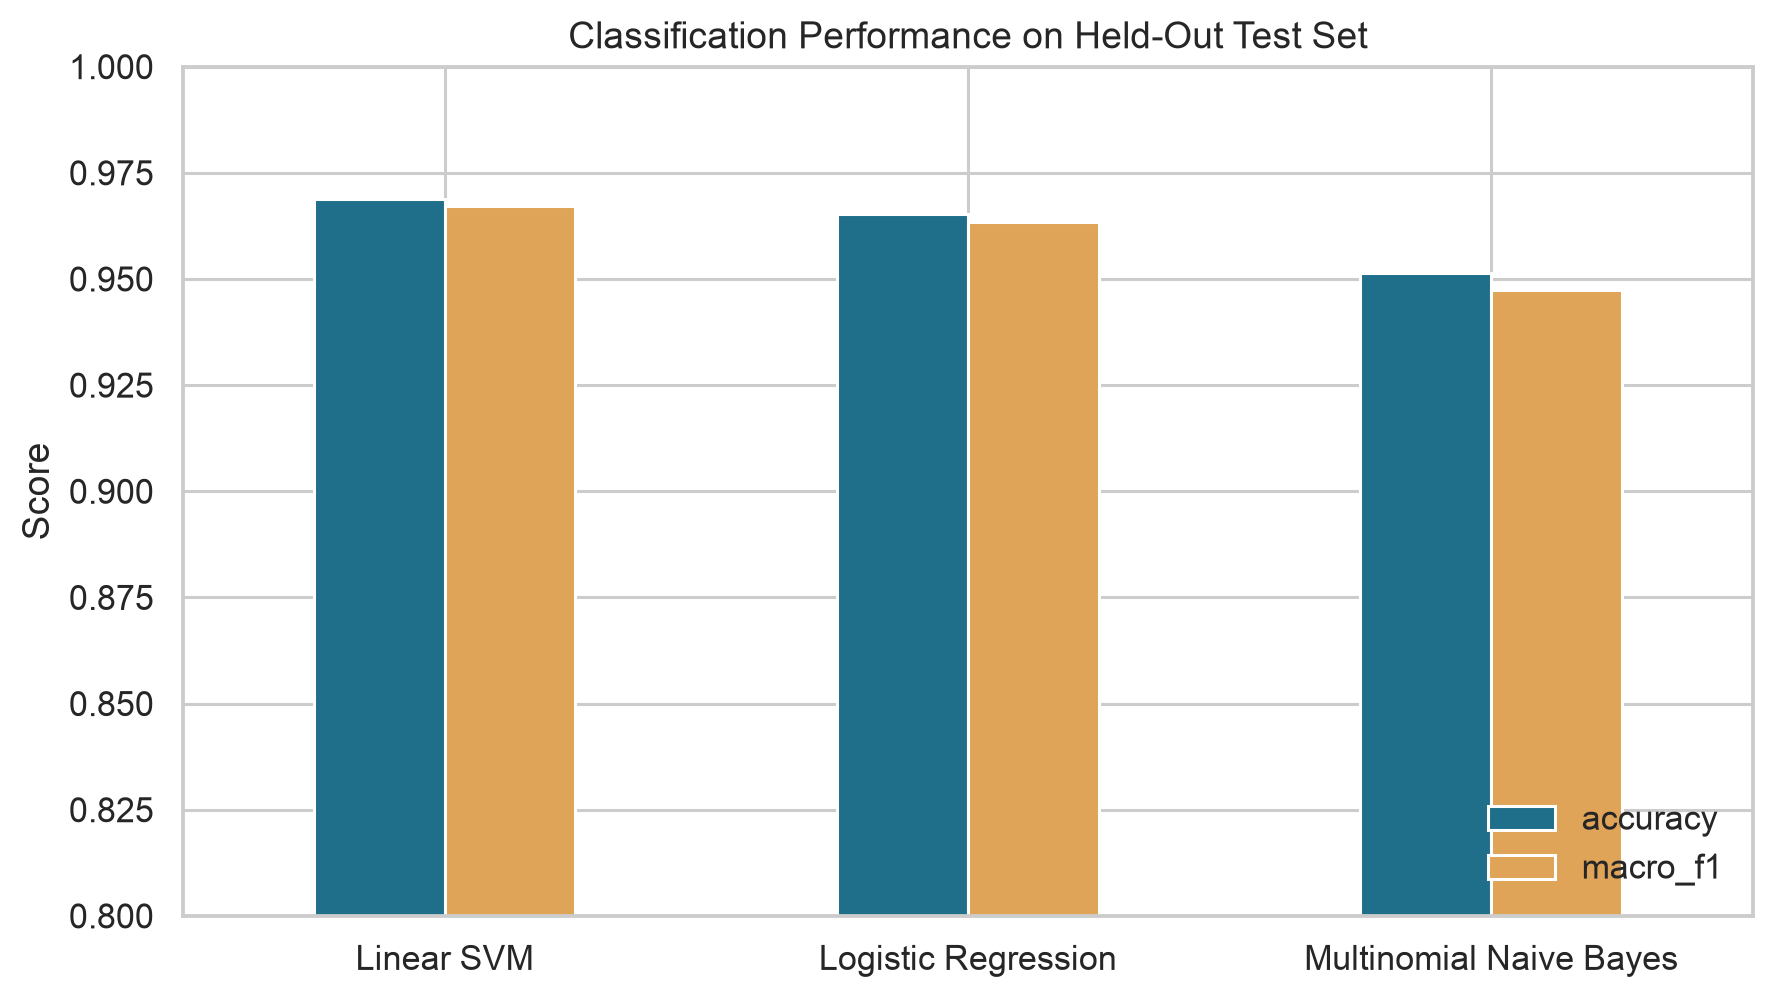

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/02_model_comparison.png'))

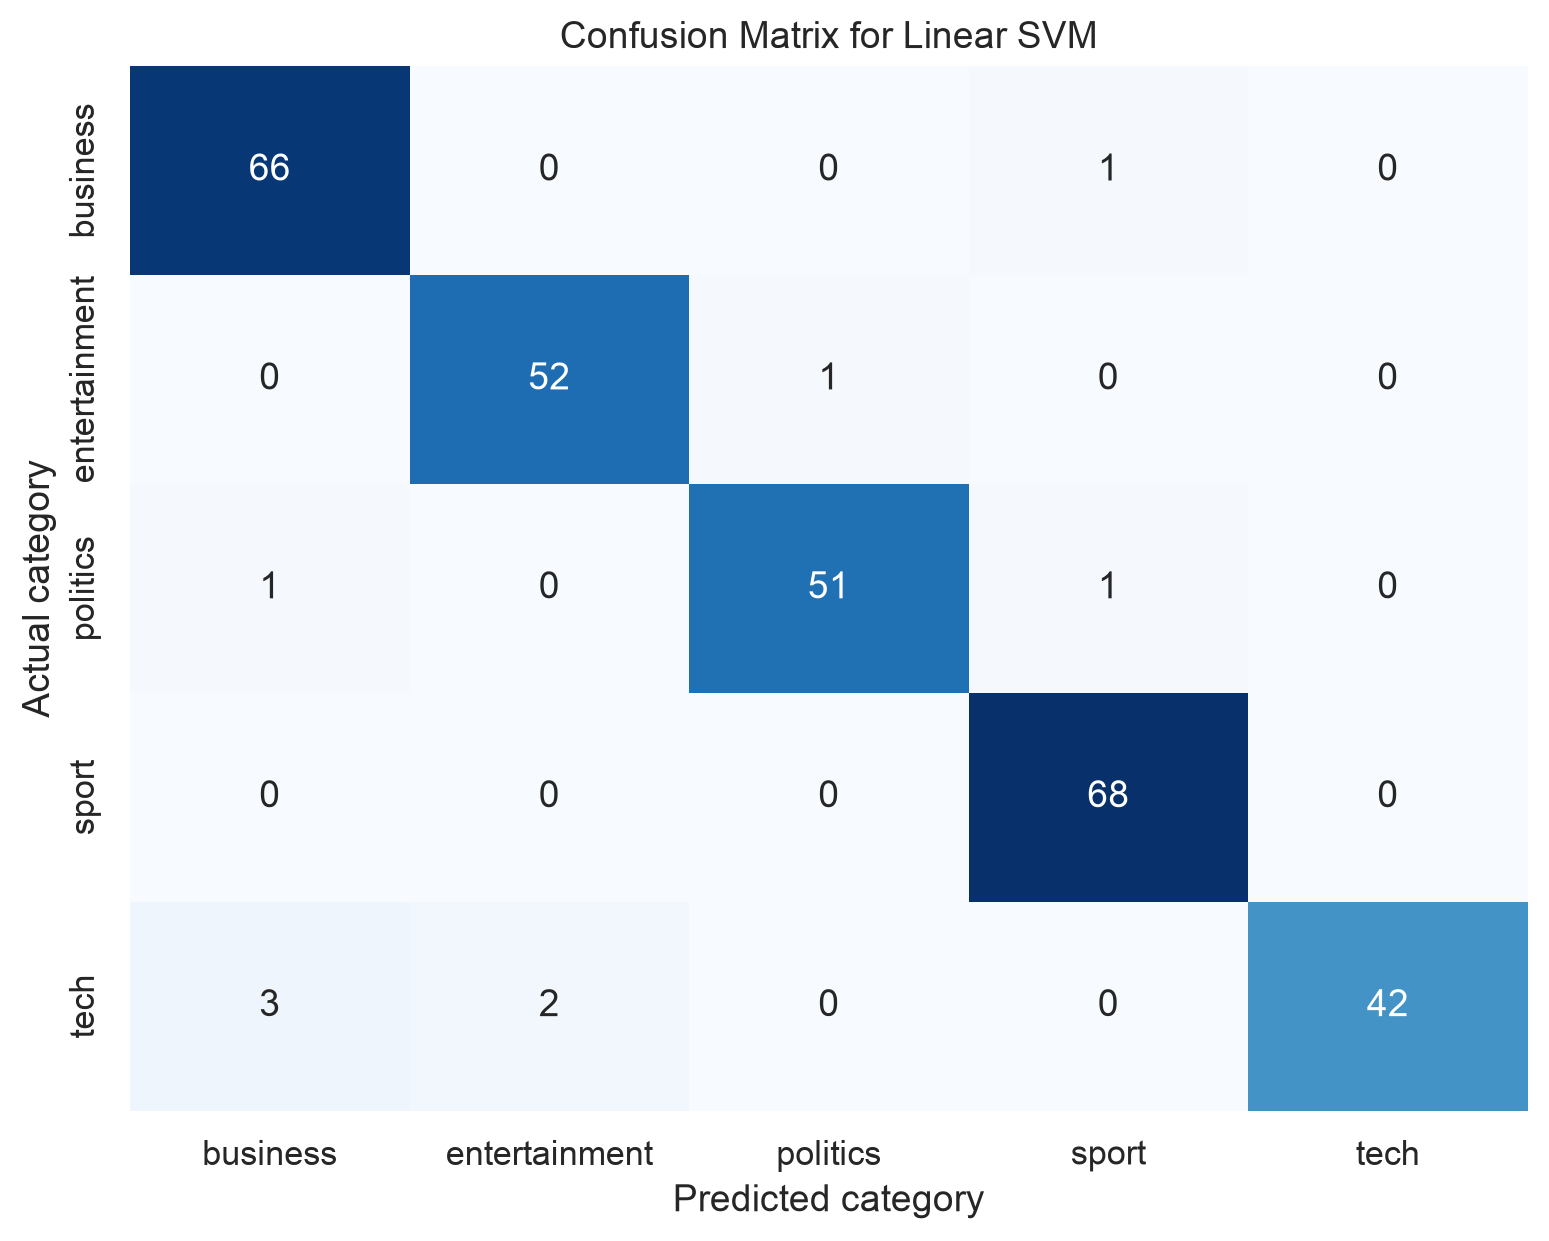

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/03_confusion_matrix.png'))

## 7 Named entity recognition

spaCy extracts PERSON, ORG, GPE, DATE, and MONEY mentions. The chart compares raw mentions in the balanced 500-article analysis sample. Entity signals support source monitoring, stakeholder tracking, and geographic coverage analysis.

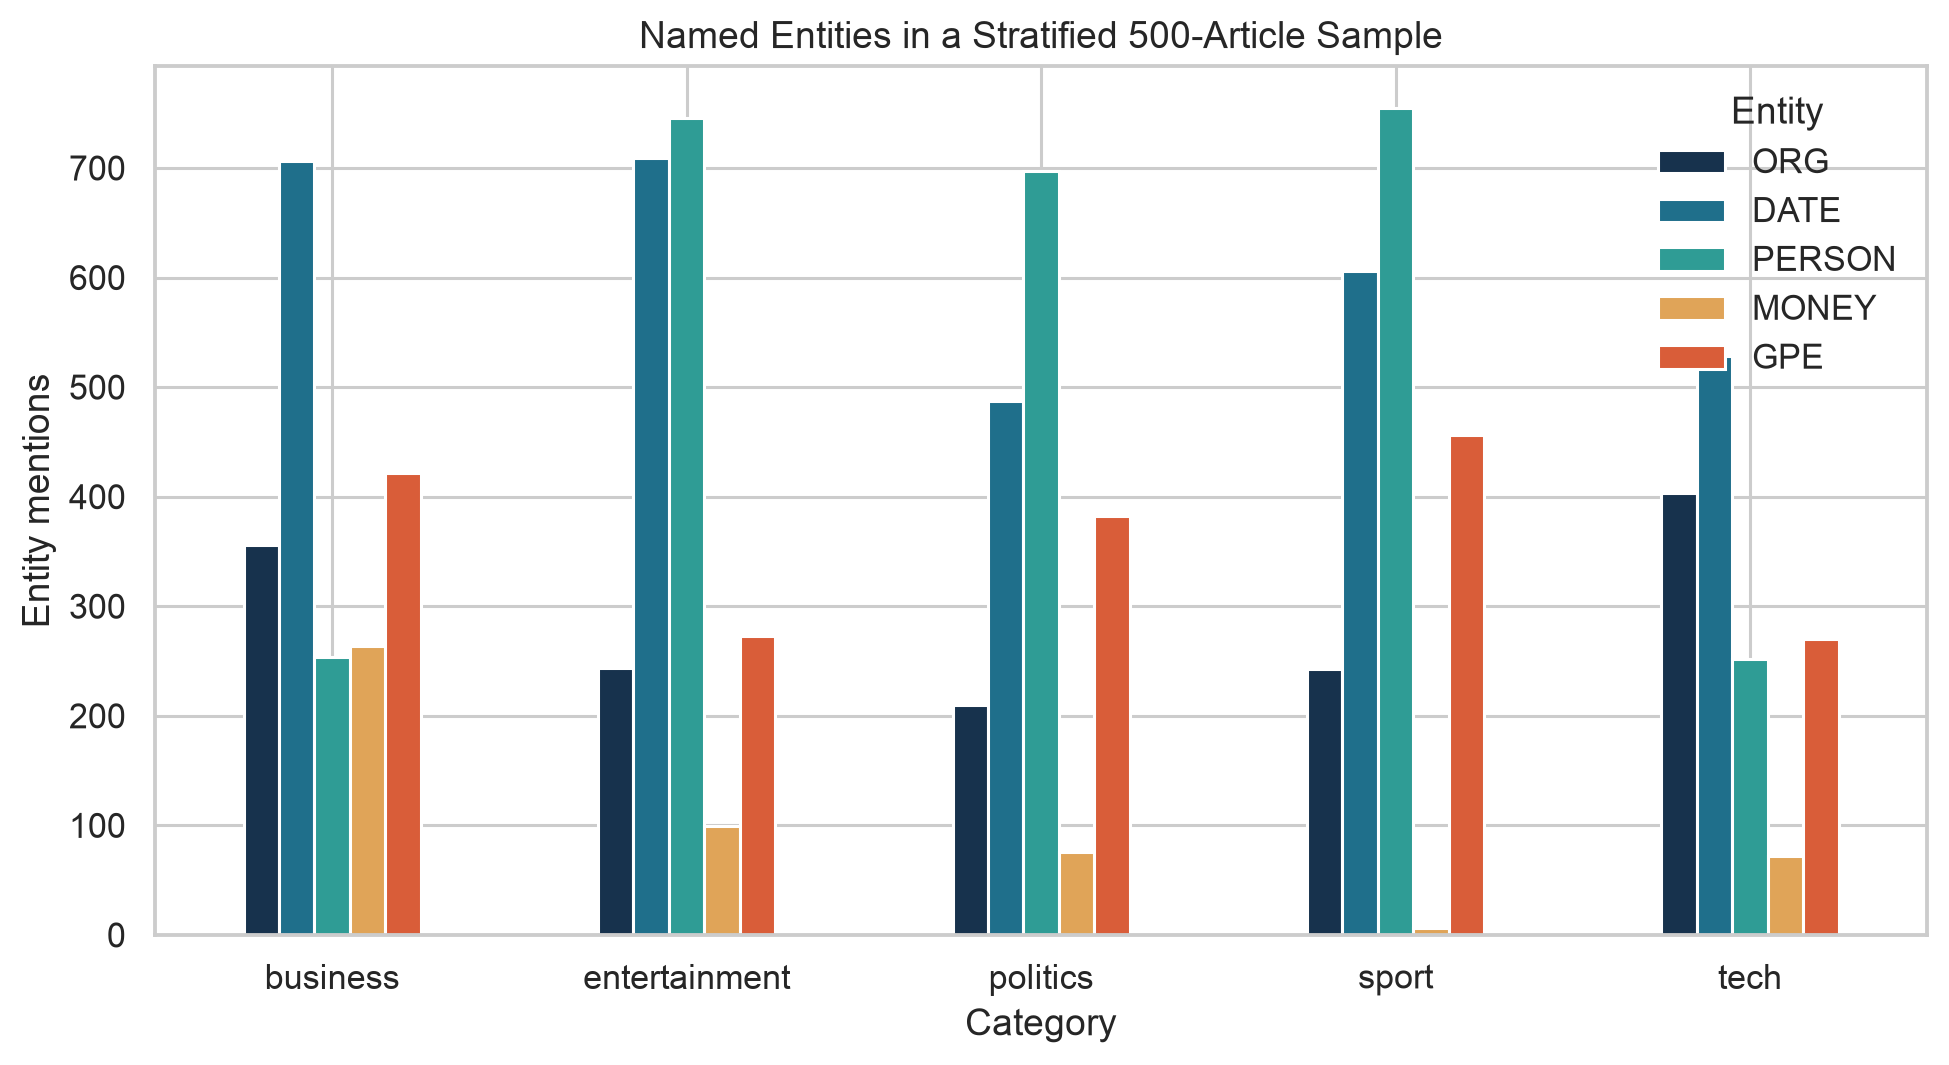

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/06_entities_by_category.png'))

## 8 Integrated inference

The saved model and `NewsBot` class combine category prediction, sentiment, entities, POS summaries, and key dependency relationships for unseen articles.

In [ ]:
from newsbot_pipeline import NewsBot
bot = NewsBot(PROJECT)
bot.analyze('The club secured a dramatic victory after its striker scored twice in the final ten minutes.')

## 9 Conclusions and responsible use

NewsBot reliably routes BBC-style articles and adds transparent linguistic evidence. Its main limitation is domain shift: the dataset reflects BBC reporting from a limited period and the sentiment lexicon can misread neutral reporting or quoted language. Production use should monitor class drift, confidence, errors by source, and entity quality. Human editorial review remains appropriate for consequential routing or reputation decisions.